<a href="https://colab.research.google.com/github/anupbagale/python-for-ai-ml/blob/main/14-trees-and-ensembles/04_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: The Rematch

In Module 12 we predicted the median house value of California neighbourhoods from the 1990 census, using linear models only. It took a whole ladder of ideas to get the error down from $97,000 to about $54,500: logarithms, ratios, smooth curves for location, a 210-feature surface over the map, and ridge regularisation to keep it under control. At the very end, an untuned gradient boosting model, given only the plain columns, did better than all of it.

This project is the rematch, done properly. Same data, same split, same metric, and the same two kinds of validation: random folds (neighbourhoods like the ones in training) and map-cell folds (regions the model has never seen). Along the way:

1. Rebuild the **benchmark**: Module 12's final linear model
2. Fit a **single tree**, and see what it does to the map
3. Grow a **random forest**, with out-of-bag error for free
4. Tune **gradient boosting** with early stopping
5. Compare everything **fairly**, on familiar and unseen regions
6. **Look inside** the winner: permutation importance and partial dependence
7. **Test** once, with an honest interval
8. Find out where trees still fall short

## Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/anupbagale/python-for-ai-ml/main/12-supervised-learning/data/california_housing.csv"
local = Path("data/california_housing.csv")
housing = pd.read_csv(local if local.exists() else DATA_URL)
print(housing.shape)

(20640, 9)


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Categorical colours, always used in this order. The first three are checked to stay
# distinguishable for the common forms of colour blindness, even in scatter plots.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

SURFACE = "#fcfcfb"     # chart background
INK = "#0b0b0b"         # titles and important text
INK_2 = "#52514e"       # labels and tick text
MUTED = "#898781"       # de-emphasised marks
GRID = "#e1e0d9"        # gridlines
AXIS = "#c3c2b7"        # axis lines

# Sequential: one hue, light to dark, for magnitude (heatmaps, counts)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "course_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
# Diverging: two opposite hues with a neutral grey in the middle, for values around zero
DIVERGING = LinearSegmentedColormap.from_list(
    "course_diverging", ["#184f95", "#86b6ef", "#f0efec", "#f0a3a2", "#c23a3a"])


def use_course_style():
    for cmap in (SEQUENTIAL, DIVERGING):
        if cmap.name not in mpl.colormaps:
            mpl.colormaps.register(cmap)
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "figure.figsize": (7, 4),
        "font.size": 10,
        "text.color": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "axes.prop_cycle": mpl.cycler(color=PALETTE),
        "lines.linewidth": 1.6,
        "lines.solid_capstyle": "round",
        "lines.markersize": 6,
        "patch.linewidth": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_2,
        "image.cmap": "course_blues",
    })


use_course_style()

## Step 1: The same data, the same split

Exactly as in Module 12: remove the 965 block groups whose value is capped at $500,001 (we don't know their true value), add the three per-household ratios, and hold out the same 20% test set with the same random seed. Every number in this project is directly comparable with Module 12's.

In [3]:
from sklearn.model_selection import KFold, PredefinedSplit, cross_val_score, train_test_split

data = housing[housing["median_house_value"] < 500_001].reset_index(drop=True)
data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
data["people_per_household"] = data["population"] / data["households"]

y_all = data["median_house_value"]
X_all = data.drop(columns="median_house_value").astype(float)     # some columns are whole numbers; trees treat them the same
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42)

cv = KFold(n_splits=5, shuffle=True, random_state=0)
cells = (np.floor(X_train["latitude"] / 0.5).astype(int) * 1000 + np.floor(X_train["longitude"] / 0.5).astype(int)).to_numpy()

# Put whole map cells into 5 folds: biggest cells first, each into the fold with the fewest rows so far
cell_sizes = pd.Series(cells).value_counts().rename_axis("cell").reset_index(name="rows")
cell_sizes = cell_sizes.sort_values(["rows", "cell"], ascending=[False, True])
fold_rows, fold_of_cell = np.zeros(5), {}
for cell, rows in zip(cell_sizes["cell"], cell_sizes["rows"]):
    fold = int(np.argmin(fold_rows))
    fold_of_cell[cell] = fold
    fold_rows[fold] += rows
spatial = PredefinedSplit([fold_of_cell[c] for c in cells])


def cv_rmse(model, splitter=cv, X=X_train, y=y_train):
    """Mean cross-validated RMSE in dollars."""
    with warnings.catch_warnings(), np.errstate(over="ignore", invalid="ignore"):
        warnings.simplefilter("ignore")
        scores = cross_val_score(model, X, y, cv=splitter, scoring="neg_root_mean_squared_error")
    return -scores.mean()


print(f"training: {len(X_train):,}   test: {len(X_test):,}   features: {X_train.shape[1]}   map cells: {len(np.unique(cells))}")
print("rows in each map-cell fold:", fold_rows.astype(int))

training: 15,740   test: 3,935   features: 11   map cells: 171
rows in each map-cell fold: [3148 3148 3148 3148 3148]


`cells` puts each block group into a square of half a degree (about 50 km), and whole squares are kept together in the folds, so in map-cell validation every prediction is for a region the model didn't train on (Module 12, Step 5).

Module 12 used `GroupKFold` for this. Different versions of scikit-learn assign groups to folds in different ways, which changes the map-cell numbers a little from one version to the next. To make this project give the same numbers everywhere, we build the folds ourselves with the classic recipe (biggest cells first, each one into the fold with the fewest rows so far) and hand them to `PredefinedSplit`. The five folds end up with almost the same number of rows.

## Step 2: The benchmark

Module 12's final model, rebuilt in one cell: logarithms of the skewed features, a smooth 210-feature surface over latitude and longitude, ridge regression with a small penalty, and a log-transformed target.

In [4]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, PolynomialFeatures, SplineTransformer, StandardScaler

SKEWED = ["median_income", "households", "rooms_per_household", "people_per_household"]
OTHER = ["housing_median_age", "bedrooms_per_room"]
LOCATION = ["longitude", "latitude"]
surface = make_pipeline(SplineTransformer(n_knots=8), PolynomialFeatures(2, interaction_only=True, include_bias=False))
linear_features = ColumnTransformer([
    ("logs", make_pipeline(FunctionTransformer(np.log, feature_names_out="one-to-one"), StandardScaler()), SKEWED),
    ("other", StandardScaler(), OTHER),
    ("location", surface, LOCATION),
])
linear_model = TransformedTargetRegressor(make_pipeline(linear_features, Ridge(alpha=0.01)), func=np.log, inverse_func=np.exp)

scoreboard = {}
scoreboard["linear (Module 12)"] = {"random folds": cv_rmse(linear_model), "map-cell folds": cv_rmse(linear_model, spatial)}
print(f"random folds:   ${scoreboard['linear (Module 12)']['random folds']:,.0f}")
print(f"map-cell folds: ${scoreboard['linear (Module 12)']['map-cell folds']:,.0f}")

random folds:   $54,455
map-cell folds: $60,077


About $54,500 on familiar neighbourhoods, exactly as in Module 12, and about $60,000 on unseen regions, close to Module 12's figure (the folds are built slightly differently). That's the score to beat.

Notice what the tree models below **won't** need: no logarithms, no scaling, no splines, no hand-made location surface. They get the raw columns plus the three ratios, and nothing else.

## Step 3: A single tree

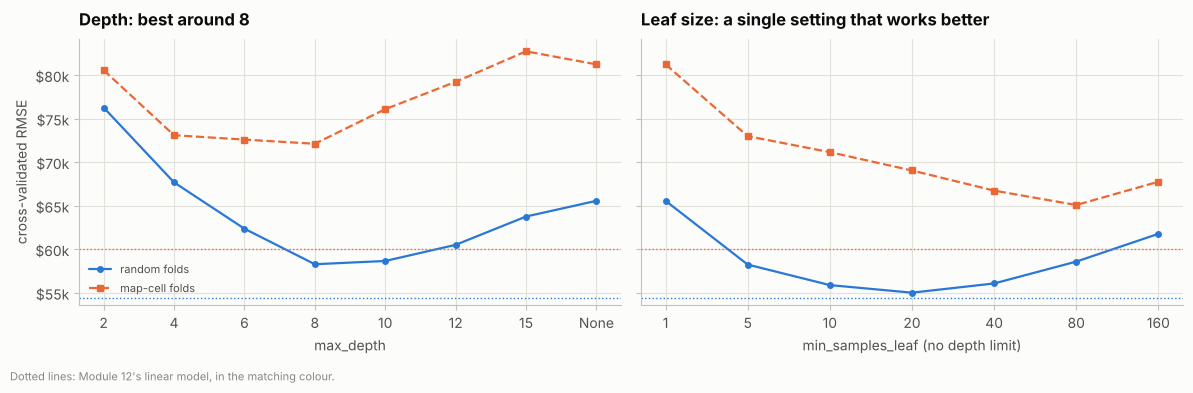

best tree: min_samples_leaf=20, random folds $55,018, map-cell folds $69,051


In [5]:
from sklearn.tree import DecisionTreeRegressor

depths = [2, 4, 6, 8, 10, 12, 15, None]
tree_random = [cv_rmse(DecisionTreeRegressor(max_depth=d, random_state=0)) for d in depths]
tree_spatial = [cv_rmse(DecisionTreeRegressor(max_depth=d, random_state=0), spatial) for d in depths]
leaf_sizes = [1, 5, 10, 20, 40, 80, 160]
leaf_random = [cv_rmse(DecisionTreeRegressor(min_samples_leaf=m, random_state=0)) for m in leaf_sizes]
leaf_spatial = [cv_rmse(DecisionTreeRegressor(min_samples_leaf=m, random_state=0), spatial) for m in leaf_sizes]

dollars = plt.FuncFormatter(lambda v, _: f"${v / 1000:.0f}k")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
labels = [str(d) for d in depths]
axes[0].plot(labels, tree_random, color=PALETTE[0], marker="o", markersize=4, label="random folds")
axes[0].plot(labels, tree_spatial, color=PALETTE[1], marker="s", markersize=4, linestyle="--", label="map-cell folds")
axes[0].set_xlabel("max_depth")
axes[0].set_title("Depth: best around 8")
axes[1].plot([str(m) for m in leaf_sizes], leaf_random, color=PALETTE[0], marker="o", markersize=4, label="random folds")
axes[1].plot([str(m) for m in leaf_sizes], leaf_spatial, color=PALETTE[1], marker="s", markersize=4, linestyle="--", label="map-cell folds")
axes[1].set_xlabel("min_samples_leaf (no depth limit)")
axes[1].set_title("Leaf size: a single setting that works better")
for ax, ref in zip(axes, ["linear (Module 12)"] * 2):
    for kind, colour in [("random folds", PALETTE[0]), ("map-cell folds", PALETTE[1])]:
        ax.axhline(scoreboard[ref][kind], color=colour, linestyle=":", linewidth=1)
    ax.yaxis.set_major_formatter(dollars)
axes[0].set_ylabel("cross-validated RMSE")
axes[0].legend(loc="lower left", fontsize=8)
fig.text(0.01, 0.01, "Dotted lines: Module 12's linear model, in the matching colour.", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

best_leaf = leaf_sizes[int(np.argmin(leaf_random))]
scoreboard["single tree"] = {"random folds": min(leaf_random), "map-cell folds": leaf_spatial[leaf_sizes.index(best_leaf)]}
print(f"best tree: min_samples_leaf={best_leaf}, random folds ${min(leaf_random):,.0f}, "
      f"map-cell folds ${scoreboard['single tree']['map-cell folds']:,.0f}")

A single tree, with one setting chosen by cross-validation and no feature engineering at all, gets within about a thousand dollars of Module 12's whole ladder on random folds. That's a striking result: the tree finds the effect of income, the curves and the location pattern on its own.

But look at the map-cell folds. On unseen regions, the tree is clearly **worse** than the linear model, by almost $9,000 at the leaf size chosen on random folds. (On unseen regions, much bigger leaves do better, a first hint that fine local detail doesn't travel.) A tree describes location as a set of rectangles, and a rectangle learnt from one region says nothing useful about a different one. The linear model's smooth surface carries over to new regions a little better.

What does a tree make of the map? Here's a tree that sees **only** latitude and longitude, next to a gradient boosting model given the same two columns:

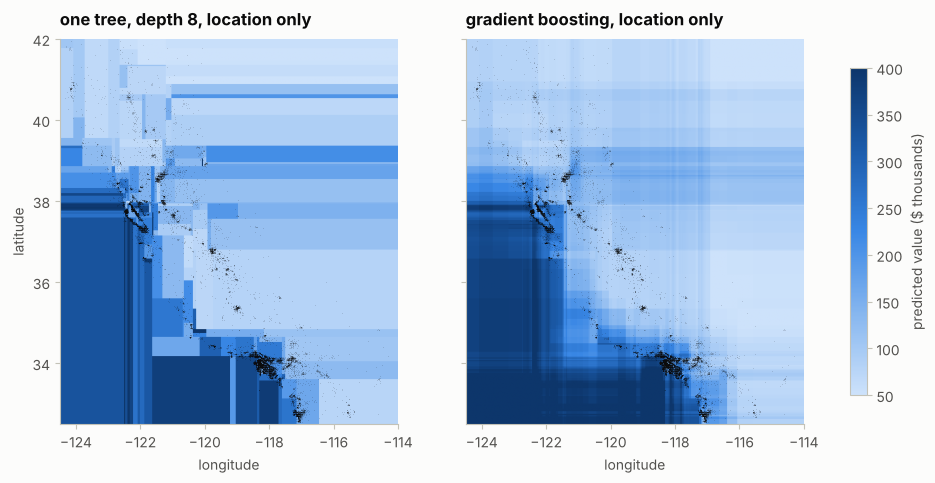

In [6]:
from sklearn.ensemble import HistGradientBoostingRegressor

lon_grid, lat_grid = np.meshgrid(np.linspace(-124.5, -114, 300), np.linspace(32.5, 42, 300))
grid = pd.DataFrame({"longitude": lon_grid.ravel(), "latitude": lat_grid.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (name, model) in zip(axes, [("one tree, depth 8", DecisionTreeRegressor(max_depth=8, random_state=0)),
                                     ("gradient boosting", HistGradientBoostingRegressor(random_state=0))]):
    model.fit(X_train[LOCATION], y_train)
    surface_values = model.predict(grid).reshape(lon_grid.shape)
    image = ax.imshow(surface_values / 1000, extent=(-124.5, -114, 32.5, 42), origin="lower", cmap=SEQUENTIAL,
                      vmin=50, vmax=400, aspect="auto")
    ax.scatter(X_train["longitude"], X_train["latitude"], s=0.3, color=INK, alpha=0.15)
    ax.grid(False)
    ax.set_xlabel("longitude")
    ax.set_title(f"{name}, location only")
axes[0].set_ylabel("latitude")
fig.colorbar(image, ax=axes, label="predicted value ($ thousands)", shrink=0.85)
plt.show()

The single tree paints the state in rectangles, with sharp jumps along straight lines of latitude and longitude. The boosted model, a sum of many small trees, builds a much finer picture: the expensive coast around San Francisco and Los Angeles stands out, and the inland valleys are cheaper. You can still see the horizontal and vertical stripes of the trees it's made of. (The dots are the training block groups; away from them, both models are guessing, and the colours there mean nothing.)

## Step 4: A random forest

A forest averages many deep trees, each trained on a bootstrap sample and choosing each split from a random subset of features. Its **out-of-bag** predictions give an error estimate without any cross-validation, and with `warm_start=True` we can add trees to the same forest and watch the OOB error as it grows:

In [7]:
from sklearn.ensemble import RandomForestRegressor

start = time.perf_counter()
forest = RandomForestRegressor(max_features=0.5, oob_score=True, warm_start=True, n_jobs=-1, random_state=0)
forest_sizes, oob_rmse = [25, 50, 100, 200, 300], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")        # with few trees, a few rows have no out-of-bag prediction yet
    for n_trees in forest_sizes:
        forest.set_params(n_estimators=n_trees).fit(X_train, y_train)
        oob_rmse.append(np.sqrt(np.mean((y_train - forest.oob_prediction_) ** 2)))
print(f"({time.perf_counter() - start:.0f} seconds)")
for n_trees, rmse in zip(forest_sizes, oob_rmse):
    print(f"{n_trees:>4} trees: out-of-bag RMSE ${rmse:,.0f}")

(14 seconds)
  25 trees: out-of-bag RMSE $49,139
  50 trees: out-of-bag RMSE $46,915
 100 trees: out-of-bag RMSE $46,242
 200 trees: out-of-bag RMSE $45,724
 300 trees: out-of-bag RMSE $45,602


More trees help less and less: going from 100 to 300 trees improves the error by well under a thousand dollars, and costs three times as much time. Adding trees never makes a forest worse, so the only question is how long you're willing to wait.

The one setting worth tuning is `max_features`, the share of features each split may choose from. OOB error makes this cheap to check:

In [8]:
oob_by_features = {}
for share in [1.0, 0.5, 0.33]:
    model = RandomForestRegressor(n_estimators=100, max_features=share, oob_score=True, n_jobs=-1, random_state=0).fit(X_train, y_train)
    oob_by_features[share] = np.sqrt(np.mean((y_train - model.oob_prediction_) ** 2))
    print(f"max_features={share}: out-of-bag RMSE ${oob_by_features[share]:,.0f}")

forest_model = RandomForestRegressor(n_estimators=100, max_features=0.5, n_jobs=-1, random_state=0)
scoreboard["random forest"] = {"random folds": cv_rmse(forest_model), "map-cell folds": cv_rmse(forest_model, spatial)}
print(f"\nrandom folds:   ${scoreboard['random forest']['random folds']:,.0f}   (compare the out-of-bag ${oob_by_features[0.5]:,.0f})")
print(f"map-cell folds: ${scoreboard['random forest']['map-cell folds']:,.0f}")

max_features=1.0: out-of-bag RMSE $46,268


max_features=0.5: out-of-bag RMSE $46,242


max_features=0.33: out-of-bag RMSE $47,134



random folds:   $46,219   (compare the out-of-bag $46,242)
map-cell folds: $55,629


Three things to notice:

- Using half the features at each split is about as good as using all of them (plain bagging), and a third is worse. With only 11 features, several of them strong, there's less to gain from decorrelating the trees than in the lesson's example.
- **The OOB error agrees with random-fold cross-validation**, so the forest's free estimate is a trustworthy shortcut, for the question random folds answer.
- **It can't answer the other question.** OOB examples are random rows, whose neighbours are in the training data. On unseen regions the forest's error is about $9,000 higher. No free estimate replaces thinking about what "new data" means.

The forest beats the linear model by about $8,000 on familiar neighbourhoods, and still beats it on unseen regions, by a smaller margin.

## Step 5: Gradient boosting

Module 12's preview used `HistGradientBoostingRegressor` with its defaults, which stop after 100 trees. Is that enough? With early stopping, the model keeps a validation set aside and keeps adding trees until the validation error stops improving. Here's the validation error tree by tree, for three learning rates:

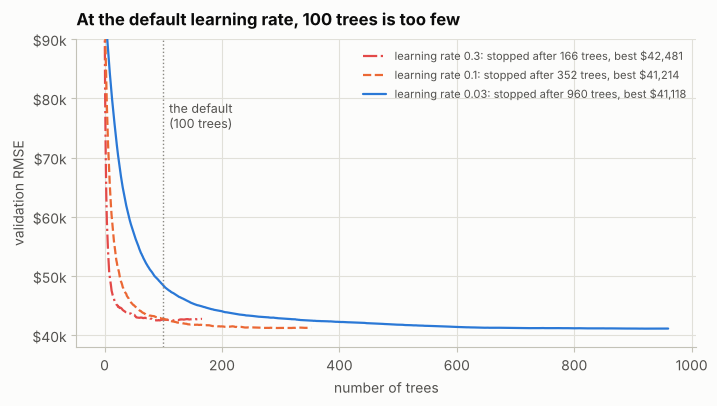

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
for rate, colour, style in [(0.3, PALETTE[7], "-."), (0.1, PALETTE[1], "--"), (0.03, PALETTE[0], "-")]:
    model = HistGradientBoostingRegressor(learning_rate=rate, max_iter=3000, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=50, scoring="neg_root_mean_squared_error", random_state=0)
    model.fit(X_train, y_train)
    validation_rmse = -model.validation_score_
    ax.plot(np.arange(len(validation_rmse)), validation_rmse, color=colour, linestyle=style,
            label=f"learning rate {rate}: stopped after {model.n_iter_} trees, best ${validation_rmse.min():,.0f}")
ax.axvline(100, color=MUTED, linestyle=":", linewidth=1)
ax.text(110, 75_000, "the default\n(100 trees)", color=INK_2, fontsize=9)
ax.set_ylim(38_000, 90_000)
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("number of trees")
ax.set_ylabel("validation RMSE")
ax.legend(loc="upper right", fontsize=8)
ax.set_title("At the default learning rate, 100 trees is too few")
plt.show()

With the default learning rate of 0.1, the validation error is still falling at 100 trees, so the default stops too early. Early stopping lets the model run on until there's no more to gain. A smaller learning rate takes more trees and ends a little lower; a larger one stops early at a worse error.

Now a small search over the two settings that matter most, the learning rate and the size of each tree, with early stopping deciding the number of trees each time:

In [10]:
start = time.perf_counter()
boosting_results = {}
for rate in [0.1, 0.05]:
    for leaves in [15, 31, 63]:
        model = HistGradientBoostingRegressor(learning_rate=rate, max_leaf_nodes=leaves, max_iter=3000, early_stopping=True,
                                              n_iter_no_change=50, random_state=0)
        boosting_results[(rate, leaves)] = cv_rmse(model)
print(f"({time.perf_counter() - start:.0f} seconds)")
table = pd.Series(boosting_results).unstack().round(0)
table.index.name, table.columns.name = "learning rate", "max_leaf_nodes"
print(table.to_string())
best_rate, best_leaves = min(boosting_results, key=boosting_results.get)
print(f"\ndefault settings (100 trees): ${cv_rmse(HistGradientBoostingRegressor(random_state=0)):,.0f}")
print(f"best: learning rate {best_rate}, {best_leaves} leaves: ${boosting_results[(best_rate, best_leaves)]:,.0f}")

(51 seconds)
max_leaf_nodes       15       31       63
learning rate                            
0.05            41789.0  41732.0  41612.0
0.10            41951.0  41807.0  41894.0



default settings (100 trees): $43,062
best: learning rate 0.05, 63 leaves: $41,612


All six combinations land within a few hundred dollars of each other, and all beat the 100-tree default. That's typical of gradient boosting with early stopping: once the number of trees is chosen well, the other settings matter much less. Tuning further (leaf sizes, regularisation) might gain a few hundred dollars more, which isn't worth chasing here.

In [11]:
boosting_model = HistGradientBoostingRegressor(learning_rate=best_rate, max_leaf_nodes=best_leaves, max_iter=3000,
                                               early_stopping=True, n_iter_no_change=50, random_state=0)
scoreboard["gradient boosting"] = {"random folds": boosting_results[(best_rate, best_leaves)],
                                   "map-cell folds": cv_rmse(boosting_model, spatial)}
print(f"map-cell folds: ${scoreboard['gradient boosting']['map-cell folds']:,.0f}")

map-cell folds: $55,033


## Step 6: The scoreboard

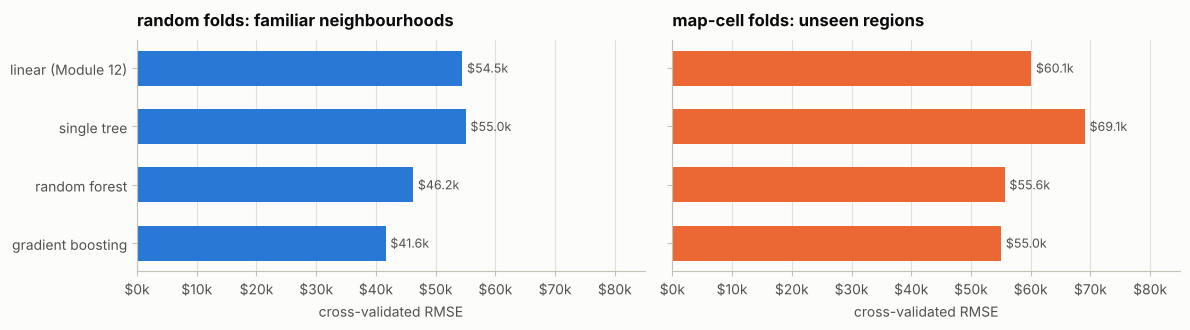

,random folds,map-cell folds,"gain over linear, random","gain over linear, map-cell"
linear (Module 12),54455.0,60077.0,0.000,0.000
single tree,55018.0,69051.0,-0.010,-0.149
random forest,46219.0,55629.0,0.151,0.074
gradient boosting,41612.0,55033.0,0.236,0.084


In [12]:
board = pd.DataFrame(scoreboard).T
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, kind, colour in [(axes[0], "random folds", PALETTE[0]), (axes[1], "map-cell folds", PALETTE[1])]:
    values = board[kind]
    ax.barh(board.index[::-1], values[::-1], color=colour, height=0.6)
    for i, v in enumerate(values[::-1]):
        ax.text(v + 800, i, f"${v / 1000:.1f}k", va="center", color=INK_2, fontsize=9)
    ax.set_xlim(0, 85_000)
    ax.xaxis.set_major_formatter(dollars)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{kind}: {'familiar neighbourhoods' if kind == 'random folds' else 'unseen regions'}")
    ax.set_xlabel("cross-validated RMSE")
fig.tight_layout()
plt.show()

board["gain over linear, random"] = 1 - board["random folds"] / board.loc["linear (Module 12)", "random folds"]
board["gain over linear, map-cell"] = 1 - board["map-cell folds"] / board.loc["linear (Module 12)", "map-cell folds"]
board.round({"random folds": 0, "map-cell folds": 0, "gain over linear, random": 3, "gain over linear, map-cell": 3})

The verdict:

- **On familiar neighbourhoods, the ensembles win clearly.** Gradient boosting cuts the error by almost a quarter compared with Module 12's carefully engineered linear model, and the random forest isn't far behind.
- **On unseen regions, the gap shrinks a lot.** Gradient boosting is still the best, with the forest close behind, but their advantage over the linear model is only about a third as big, and the single tree is by far the worst. Much of what the tree models gain on random folds comes from **remembering local detail**: which neighbourhoods are expensive. That detail is real and useful when you predict for places like the ones in training, and of little use for a region you've never seen.
- **Every model is worse on unseen regions.** No choice of model removes that; it's a property of the question.

So which model would you recommend? For predicting values in areas covered by the training data, such as filling gaps in a survey, gradient boosting is clearly better. For a new region, every model's error is around $54,000 to $69,000, and you'd want to tell the user that, whichever model you picked.

## Step 7: Look inside the winner

Tree ensembles don't have weights to read, so we use the two tools from the lesson. For a fair look, hold out part of the training data as a validation set, fit on the rest, and compute **permutation importance** on the validation set:

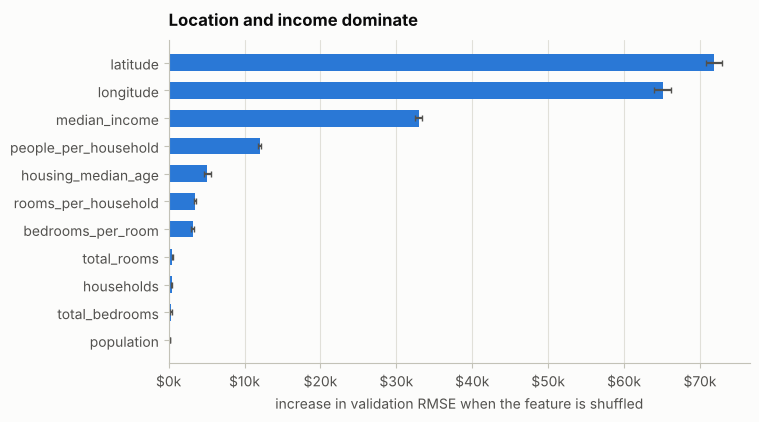

In [13]:
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

X_fit, X_valid, y_fit, y_valid = train_test_split(X_train, y_train, test_size=0.2, random_state=1)
inspect_model = boosting_model.fit(X_fit, y_fit)
perm = permutation_importance(inspect_model, X_valid, y_valid, n_repeats=5, random_state=0,
                              scoring="neg_root_mean_squared_error")
importance = pd.Series(perm.importances_mean, index=X_train.columns).sort_values()
spread = pd.Series(perm.importances_std, index=X_train.columns).loc[importance.index]

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(importance.index, importance, xerr=spread, color=PALETTE[0], height=0.6, error_kw={"ecolor": INK_2, "capsize": 2})
ax.xaxis.set_major_formatter(dollars)
ax.grid(axis="y", visible=False)
ax.set_xlabel("increase in validation RMSE when the feature is shuffled")
ax.set_title("Location and income dominate")
plt.show()

Shuffling **latitude** or **longitude** raises the error by more than any other feature: location is the model's most important information, as it was for the linear model, and here the trees find it without a hand-made surface. **Median income** is next. The other features each matter much less individually.

A caution from the lesson: correlated features share credit. The totals (rooms, bedrooms, households, population) carry overlapping information, so each one looks less important than the group really is.

**Partial dependence** shows the shape of each effect: the model's average prediction as one feature varies, with everything else as it is in the data. The thin lines show individual block groups (ICE curves), so you can see whether the average hides different behaviours:

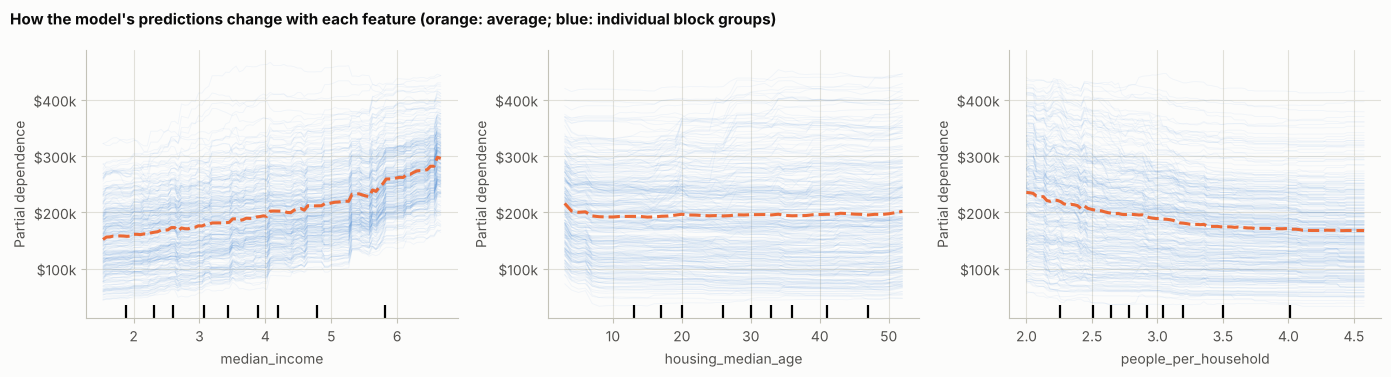

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sample = X_valid.sample(300, random_state=0)
PartialDependenceDisplay.from_estimator(
    inspect_model, sample, ["median_income", "housing_median_age", "people_per_household"], kind="both",
    ax=axes, ice_lines_kw={"color": PALETTE[0], "alpha": 0.06, "linewidth": 0.6},
    pd_line_kw={"color": PALETTE[1], "linewidth": 2.2})
for ax in np.ravel(axes):
    ax.yaxis.set_major_formatter(dollars)
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()
fig.suptitle("How the model's predictions change with each feature (orange: average; blue: individual block groups)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

What the model learnt, read from the curves:

- **Income**: predicted value rises steadily across the whole range, from about $150,000 to about $300,000 on average, and a little more steeply for the highest incomes. (The plots cover the middle 90% of each feature's values; the black ticks at the bottom mark every tenth percentile.)
- **Housing age**: almost flat. Once location and the other features are known, the age of the housing adds little, apart from the very newest neighbourhoods, which are valued a little higher.
- **People per household**: values fall as households get more crowded, steeply at first and then levelling off.

The individual curves mostly run parallel to the average, shifted up or down. Shifting means location and other features set the level, and parallel means the shape of each effect is similar everywhere. Where they fan out, the effect depends on other features: an interaction the trees found on their own.

Remember what these plots are: a description of the **model**, which learnt from 1990 census patterns. They're not proof that, say, income **causes** house values to rise in that exact way.

## Step 8: Test once

Every choice is made. Fit each model on the whole training set and evaluate on the test set:

In [15]:
final_models = {
    "linear (Module 12)": linear_model,
    "single tree": DecisionTreeRegressor(min_samples_leaf=best_leaf, random_state=0),
    "random forest": forest_model,
    "gradient boosting": boosting_model,
}
test_predictions, rows = {}, {}
for name, model in final_models.items():
    with warnings.catch_warnings(), np.errstate(over="ignore"):
        warnings.simplefilter("ignore")
        test_predictions[name] = model.fit(X_train, y_train).predict(X_test)
    errors = y_test.to_numpy() - test_predictions[name]
    rows[name] = {"test RMSE": np.sqrt(np.mean(errors ** 2)), "test MAE": np.mean(np.abs(errors)),
                  "R²": 1 - np.sum(errors ** 2) / np.sum((y_test - y_test.mean()) ** 2),
                  "cross-validated RMSE": scoreboard[name]["random folds"]}
pd.DataFrame(rows).T.round({"test RMSE": 0, "test MAE": 0, "R²": 3, "cross-validated RMSE": 0})

,test RMSE,test MAE,R²,cross-validated RMSE
linear (Module 12),55755.0,38147.0,0.688,54455.0
single tree,55388.0,37522.0,0.692,55018.0
random forest,47015.0,32075.0,0.778,46219.0
gradient boosting,41826.0,28034.0,0.825,41612.0


The test results match the cross-validation estimates closely for every model, so the comparison was honest. Gradient boosting has a typical error (MAE) of under $30,000 and explains more than 80% of the variation in house values, against about 70% for the linear model.

Is the improvement over the linear model real, or could it be luck in which block groups ended up in the test set? A paired bootstrap (Module 13) resamples the test block groups and scores both models on the same resample each time:

In [16]:
rng = np.random.default_rng(0)
y_arr = y_test.to_numpy()
err_linear = y_arr - test_predictions["linear (Module 12)"]
err_boost = y_arr - test_predictions["gradient boosting"]
differences = []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    differences.append(np.sqrt(np.mean(err_linear[idx] ** 2)) - np.sqrt(np.mean(err_boost[idx] ** 2)))
low, high = np.percentile(differences, [2.5, 97.5])
print(f"RMSE improvement of gradient boosting over linear: ${np.mean(differences):,.0f}   (95% interval ${low:,.0f} to ${high:,.0f})")

RMSE improvement of gradient boosting over linear: $13,952   (95% interval $12,474 to $15,409)


The interval is far from zero: on block groups like these, gradient boosting's advantage of more than $10,000 in RMSE is not luck.

## Step 9: Where trees still fall short

Two limits from the lesson show up in this data.

**They can't predict beyond the training range.** The capped block groups were removed, so no training value is above $500,000. A tree's prediction is an average of training values, so it can never go higher, however rich and coastal a neighbourhood is. The linear model works on the log scale and can extrapolate beyond the range, for better or worse:

In [17]:
for name in ["linear (Module 12)", "random forest", "gradient boosting"]:
    print(f"{name:<20} highest test prediction: ${test_predictions[name].max():>9,.0f}")
print(f"{'':<20} highest training value: ${y_train.max():>10,.0f}")

linear (Module 12)   highest test prediction: $  560,176
random forest        highest test prediction: $  450,947
gradient boosting    highest test prediction: $  463,103
                     highest training value: $   500,000


Neither tree model gets near the highest training value on the test set. A forest **can't** exceed it at all, because each tree predicts an average of training values; boosting adds up corrections and could drift slightly past it, but not far. The linear model's highest prediction goes beyond the training range. For the capped neighbourhoods we removed, whose true values are above $500,000, every model here would be wrong, and the trees would be wrong in a predictable way: too low.

**They're bigger and slower.** The linear model is about 220 numbers. The tuned boosting model is hundreds of trees with dozens of leaves each, and the forest stores 100 fully grown trees:

In [18]:
import pickle

for name in ["linear (Module 12)", "random forest", "gradient boosting"]:
    size_mb = len(pickle.dumps(final_models[name])) / 1e6
    start = time.perf_counter()
    final_models[name].predict(X_test)
    print(f"{name:<20} size {size_mb:7.2f} MB   predicts {len(X_test):,} block groups in {time.perf_counter() - start:.3f} seconds")

linear (Module 12)   size    0.01 MB   predicts 3,935 block groups in 0.029 seconds


random forest        size  142.22 MB   predicts 3,935 block groups in 0.097 seconds
gradient boosting    size    2.43 MB   predicts 3,935 block groups in 0.065 seconds


Every model predicts thousands of block groups in a fraction of a second, so speed isn't a problem here. Size is another matter: the forest takes well over 100 MB, because each of its 100 trees grows until its leaves hold only a few block groups, and the trees together have millions of nodes. The boosting model is more accurate and around 60 times smaller. That difference matters when a model has to be stored, shipped or loaded by a web service (Module 11), and it's one reason gradient boosting is often preferred in production. (A forest can be shrunk a lot with `min_samples_leaf` or `max_depth`, usually at a small cost in accuracy.)

## What we learned

- **A single tree, untuned except for its leaf size, matched a whole module of linear feature engineering** on familiar data, because trees find curves, interactions and location patterns on their own.
- **Ensembles beat the best linear model by a wide margin**: the random forest by about 15% and tuned gradient boosting by almost a quarter on random folds, confirmed on the test set with a paired bootstrap.
- **Early stopping mattered more than other tuning**: the default 100 trees stopped too early, and once the number of trees was chosen by validation, the learning rate and tree size made little difference.
- **OOB error is a free and accurate estimate**, but only of the random-fold question.
- **On unseen regions, the advantage of trees shrinks** and the single tree falls behind the linear model, because much of what trees learn is local detail.
- **Permutation importance and partial dependence** showed a model that relies mostly on location and income, with crowding next, and housing age adding little once the rest is known.
- **Trees can't extrapolate**: no forest prediction can exceed the highest training value. And a forest of fully grown trees can be very large: here over 100 MB, against 2.4 MB for the more accurate boosting model.

### Ideas to go further

1. Add the capped block groups back in, with their value set to $500,001. How does each model handle them? Which kind of model is hurt more?
2. Train gradient boosting on the **log** of the value (`TransformedTargetRegressor`). Does it help on random folds? On map-cell folds?
3. Tune gradient boosting using **map-cell** folds instead of random folds. Do different settings win when the goal is unseen regions?
4. Combine the models: average the predictions of the linear model and gradient boosting. Does the average beat both? (This is called **blending**, and it often works when models make different kinds of mistakes.)
5. Install LightGBM or XGBoost (`pip install lightgbm`) and compare it with `HistGradientBoostingRegressor` on the same folds.

Data: R. Kelley Pace and Ronald Barry (1997), built from the 1990 US Census and distributed through StatLib. Details in [Module 12's data folder](../12-supervised-learning/data/README.md).